<a href="https://colab.research.google.com/github/akhil7981/ML_LAB_2026-27/blob/main/data_visuals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import Isomap
from sklearn.preprocessing import StandardScaler

# Generate sample data
np.random.seed(42)
data = {
    'Category': np.random.choice(['A', 'B', 'C', 'D'], size=100),
    'Value1': np.random.randint(10, 100, size=100),
    'Value2': np.random.uniform(5.0, 50.0, size=100),
    'Feature1': np.random.randn(100) * 10 + 50,
    'Feature2': np.random.randn(100) * 5 + 20,
    'Feature3': np.random.randn(100) * 2 + 10
}
df = pd.DataFrame(data)

display(df.head())


,Category,Value1,Value2,Feature1,Feature2,Feature3
0,C,72,44.747612,58.672295,14.827988,8.596373
1,D,27,19.595526,59.584138,21.021415,8.065778
2,A,99,10.493958,54.181185,22.406089,12.873509
3,C,53,21.033403,31.134720,22.335286,8.596600
4,C,43,45.807280,72.733452,25.685087,9.713433


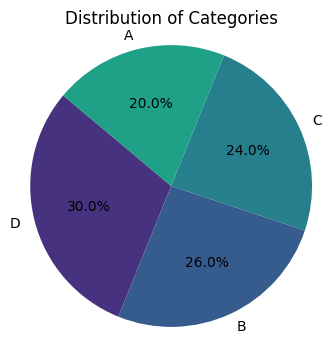

In [7]:
# Prepare data for pie chart: count occurrences of each category
pie_data = df['Category'].value_counts()

plt.figure(figsize=(4, 4))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis'))
plt.title('Distribution of Categories')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()


/tmp/ipykernel_713/1432926826.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bar_data.index, y=bar_data.values, palette='plasma')


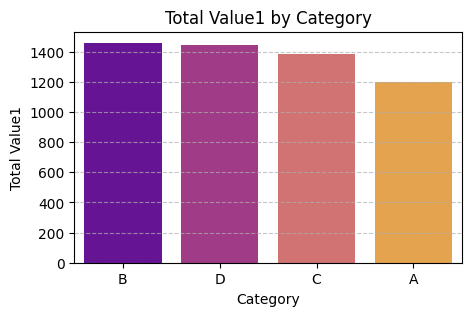

In [8]:
# Prepare data for bar chart: sum of 'Value1' per category
bar_data = df.groupby('Category')['Value1'].sum().sort_values(ascending=False)

plt.figure(figsize=(5, 3))
sns.barplot(x=bar_data.index, y=bar_data.values, palette='plasma')
plt.title('Total Value1 by Category')
plt.xlabel('Category')
plt.ylabel('Total Value1')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


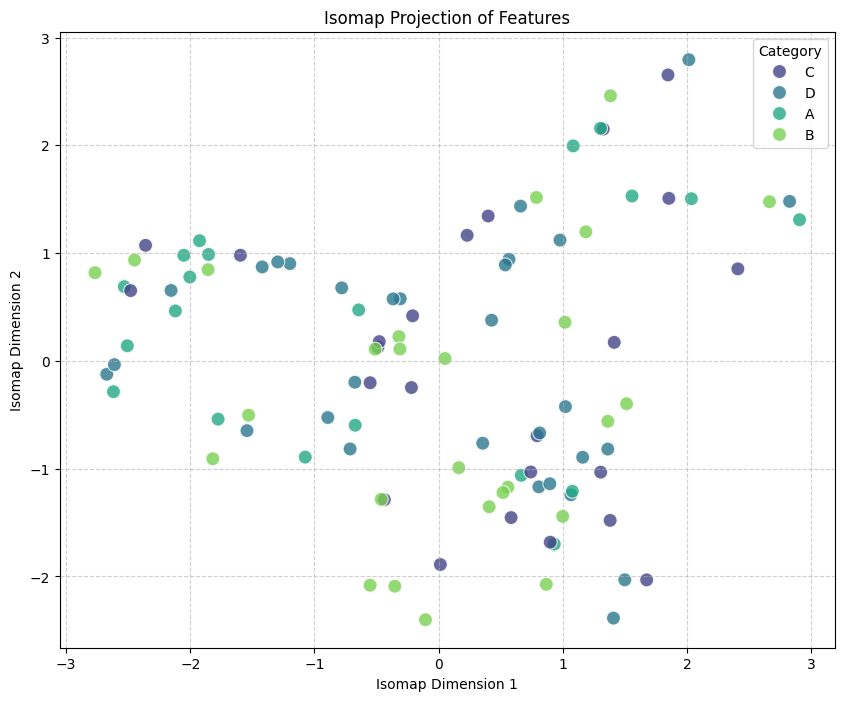

In [10]:
# Prepare data for Isomap: Use numerical features for dimensionality reduction
features_for_isomap = df[['Feature1', 'Feature2', 'Feature3']]

# It's good practice to scale data before applying Isomap
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_for_isomap)

# Apply Isomap to reduce to 2 dimensions
isomap = Isomap(n_components=2, n_neighbors=5) # n_neighbors is an important parameter
isomap_data = isomap.fit_transform(scaled_features)

# Create a DataFrame for the Isomap results for easier plotting
isomap_df = pd.DataFrame(data=isomap_data, columns=['Isomap_Dim1', 'Isomap_Dim2'])
isomap_df['Category'] = df['Category'] # Add original category for coloring

plt.figure(figsize=(10, 8))
sns.scatterplot(x='Isomap_Dim1', y='Isomap_Dim2', hue='Category', data=isomap_df, palette='viridis', s=100, alpha=0.8)
plt.title('Isomap Projection of Features')
plt.xlabel('Isomap Dimension 1')
plt.ylabel('Isomap Dimension 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


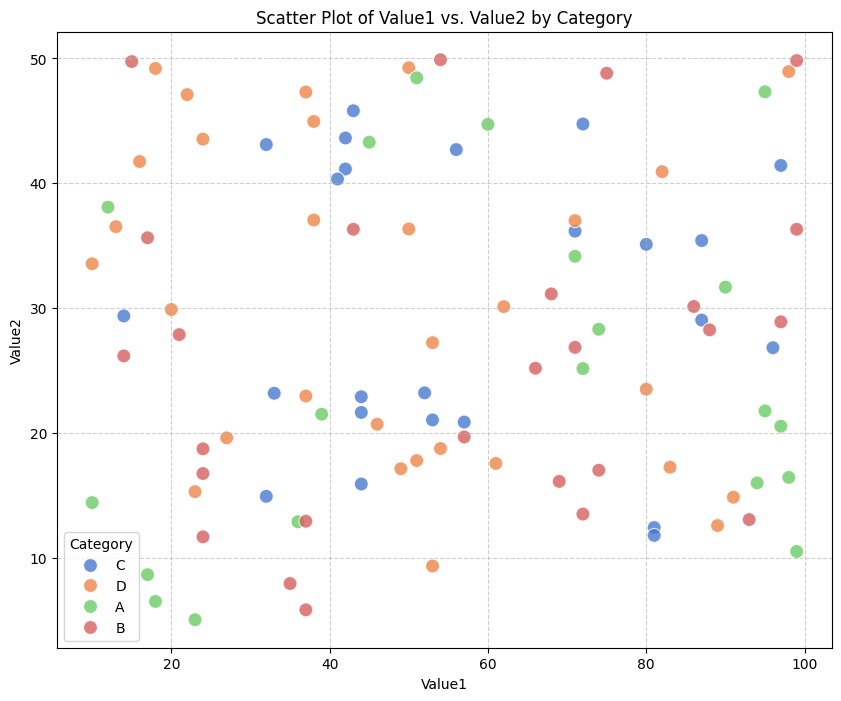

In [5]:
# Create a scatter plot to show the relationship between 'Value1' and 'Value2', colored by 'Category'
plt.figure(figsize=(10, 8))
sns.scatterplot(x='Value1', y='Value2', hue='Category', data=df, s=100, alpha=0.8, palette='muted')
plt.title('Scatter Plot of Value1 vs. Value2 by Category')
plt.xlabel('Value1')
plt.ylabel('Value2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Category')
plt.show()
